In [ ]:
import numpy as np 
import pandas as pd 
import os
from datasets import load_dataset
import matplotlib.pyplot as plt 
import seaborn as sns

sns.set_theme(style="whitegrid")

In [26]:
# load dataset from hugging face
data = load_dataset("b-mc2/sql-create-context")
print(data)

#convert the data to a Pandas DataFrame
df = data["train"].to_pandas()

DatasetDict({
    train: Dataset({
        features: ['answer', 'question', 'context'],
        num_rows: 78577
    })
})


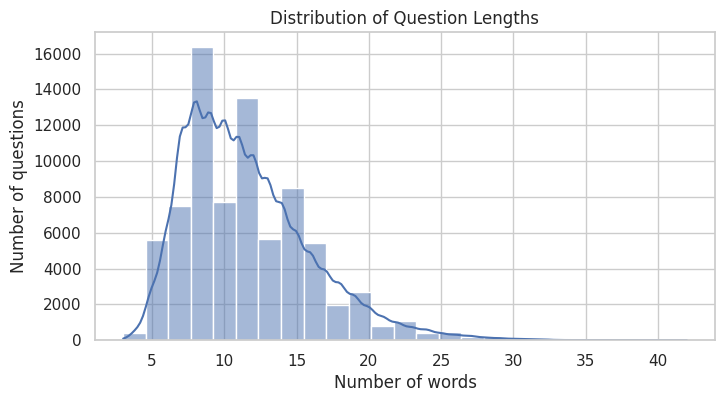


Question length (words):
count    78577.000000
mean        11.538020
std          4.401795
min          3.000000
25%          8.000000
50%         11.000000
75%         14.000000
max         42.000000
Name: question, dtype: float64


In [27]:
#Distribution of question lengths
df["question_words"] = df["question"].str.split().str.len()

plt.figure(figsize=(8, 4))
sns.histplot(df["question_words"], bins=25, kde=True)
plt.title("Distribution of Question Lengths")
plt.xlabel("Number of words")
plt.ylabel("Number of questions")
plt.show()

print("\nQuestion length (words):")
print(df["question"].str.split().str.len().describe())

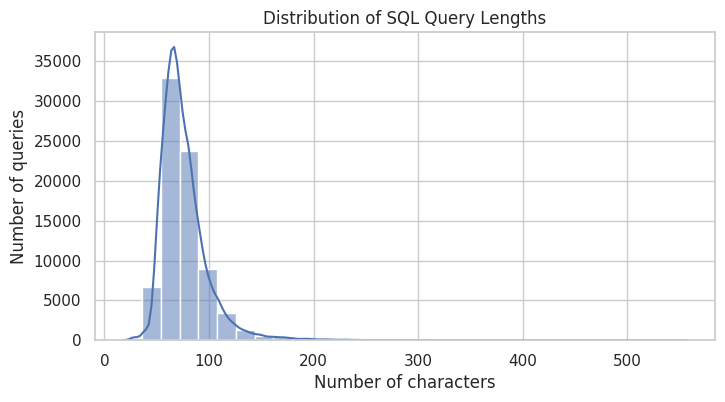


SQL length (chars):
count    78577.000000
mean        76.262672
std         24.519636
min         18.000000
25%         62.000000
50%         71.000000
75%         85.000000
max        557.000000
Name: answer, dtype: float64


In [28]:
#Distribution of SQL query lengths
df["sql_length"] = df["answer"].str.len()

plt.figure(figsize=(8, 4))
sns.histplot(df["sql_length"], bins=30, kde=True)
plt.title("Distribution of SQL Query Lengths")
plt.xlabel("Number of characters")
plt.ylabel("Number of queries")
plt.show()

print("\nSQL length (chars):")
print(df["answer"].str.len().describe())

COUNT(       10.6%
MAX(         5.6%
MIN(         5.5%
AVG(         4.0%
SUM(         3.6%
WHERE        96.3%
ORDER BY     1.4%
GROUP BY     1.5%
JOIN         2.5%
DISTINCT     0.6%
HAVING       0.4%
LIKE         0.1%
INTERSECT    0.2%
UNION        0.2%


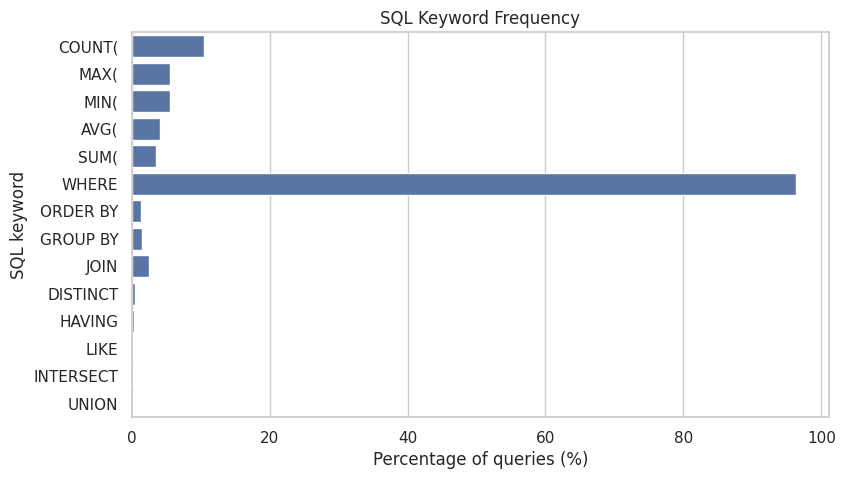

In [29]:
#Most frequent SQL keywords
keywords = ["COUNT(", "MAX(", "MIN(", "AVG(", "SUM(", "WHERE", "ORDER BY",
      "GROUP BY", "JOIN", "DISTINCT", "HAVING", "LIKE", "INTERSECT", "UNION"]

frequencies = {}

for k in keywords:
    count = df["answer"].str.upper().str.contains(k, regex=False).sum()
    percentage = count / len(df) * 100

    frequencies[k] = percentage

    print(f"{k:12s} {percentage:.1f}%")


# Plot the results
plt.figure(figsize=(9, 5))
sns.barplot(x=list(frequencies.values()),
            y=list(frequencies.keys()))
plt.title("SQL Keyword Frequency")
plt.xlabel("Percentage of queries (%)")
plt.ylabel("SQL keyword")
plt.show()

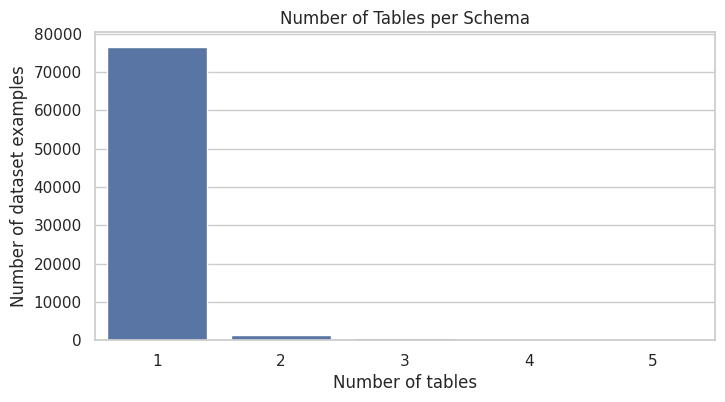


Tables per schema:
context
1    76576
2     1457
3      473
4       64
5        7
Name: count, dtype: int64


In [30]:
#Number of tables per schema
tables_per_schema = df["context"].str.count("CREATE TABLE")

plt.figure(figsize=(8, 4))
sns.countplot(x=tables_per_schema)
plt.title("Number of Tables per Schema")
plt.xlabel("Number of tables")
plt.ylabel("Number of dataset examples")
plt.show()


print("\nTables per schema:")
print(df["context"].str.count("CREATE TABLE").value_counts().sort_index())

In [31]:
print("Duplicate rows:", df.duplicated().sum())

print("Unique schemas:", df["context"].nunique())

print("Unique questions:", df["question"].nunique())

print("\nMissing values:")
print(df.isnull().sum())

Duplicate rows: 0
Unique schemas: 72947
Unique questions: 78311

Missing values:
answer            0
question          0
context           0
question_words    0
sql_length        0
dtype: int64
